# U-bolt — Punto IV: estrapolazione temporale POD-NN + DMD

La consegna (PDF *Assignments 2 - Problems description*, p. 5) chiede se il danno raggiungerà **$x^*=(3.5,2)$ a $t^*=2T=0.04$**, e in quale misura. Si considera il bullone del punto III, usando i parametri identificati dalle misure in $x_0=(0.5,3)$.

La rete approssima la mappa $(\mu,t/T)\mapsto a(t;\mu)$ soltanto per $0\leq t\leq T=0.02$. Per andare oltre $T$ identifichiamo una dinamica **DMD nei coefficienti POD**, secondo il principio del Lab 9. La rete viene interrogata esclusivamente nel suo intervallo temporale di addestramento; la DMD avanza poi da $T$ a $2T$.

Riferimenti locali:
- [u-bolt_POD-NN.ipynb](u-bolt_POD-NN.ipynb): costruzione, addestramento e verifica del ROM;
- [u-bolt_III.ipynb](u-bolt_III.ipynb): identificazione dei parametri;
- [support_functions.py](support_functions.py) e [guida](support_functions_guide.md): modello, scaling, POD, geometria e norma FEM;
- [extrapolation_functions.py](extrapolation_functions.py): fit DMD, avanzamento e backtest, separati dal notebook per leggibilità;
- `artifacts/`: pesi, base, scaler e `inverse_results.npz` già salvati. Non occorre riaddestrare la rete o eseguire gli altri notebook.

Usare il kernel **DLROMs-WSL** descritto in `../DLROMS-WSL.md`. L'esecuzione salva nuovi risultati del punto IV senza sovrascrivere quelli del punto III.

In [1]:
from pathlib import Path
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display, Markdown

# Funziona sia con cwd=Assignment2 sia con cwd=radice del progetto.
ROOT = Path.cwd() if (Path.cwd() / "support_functions.py").exists() else Path.cwd() / "Assignment2"
if not (ROOT / "support_functions.py").exists():
    raise FileNotFoundError("Aprire il notebook dalla cartella del progetto o da Assignment2.")
sys.path.insert(0, str(ROOT))
import support_functions as sf
import extrapolation_functions as ef

ARTIFACTS = ROOT / "artifacts"
OUTPUT = ARTIFACTS / "point_IV"
OUTPUT.mkdir(parents=True, exist_ok=True)
DEVICE = "cpu"
torch.set_num_threads(2)
DT, T, T_STAR = 5e-4, 0.02, 0.04
X0, X_STAR = (0.5, 3.0), (3.5, 2.0)
N_STEPS = int(round((T_STAR-T)/DT))
time_known = np.arange(int(round(T/DT))+1)*DT
time_future = T + np.arange(N_STEPS+1)*DT
assert len(time_known) == 41 and N_STEPS == 40

## 1. Modello congelato e parametri del punto III

Si caricano i parametri $\mu^*$ effettivamente salvati, senza copiarli dai valori arrotondati del Markdown. Le quantità fisiche sono $D=10^{\mu_1}$, $r=10^{\mu_2+2}$, $\delta=\mu_3+1$.

Architettura e attivazione vengono lette dai metadati del checkpoint. La base e lo scaling devono essere quelli usati per il modello: verifichiamo anche le impronte salvate nel checkpoint. La rete rimane congelata.

In [2]:
import hashlib

def fingerprint(array):
    x = np.ascontiguousarray(array)
    h = hashlib.sha256()
    h.update(str(x.shape).encode())
    h.update(x.dtype.str.encode())
    h.update(x.tobytes())
    return h.hexdigest()

Vn = np.load(ARTIFACTS / "pod_basis.npy")
with np.load(ARTIFACTS / "scaler.npz") as data:
    scaler = sf.CoefficientScaler(data["minimum"].copy(), data["scale"].copy())
checkpoint = torch.load(ARTIFACTS / "pod_nn_model.pt", map_location=DEVICE, weights_only=True)
options = checkpoint["identity"]["options"]
hashes = checkpoint["identity"]["hashes"]
for name, array in {"basis": Vn, "scaler_min": scaler.minimum, "scaler_scale": scaler.scale}.items():
    if fingerprint(array) != hashes[name]:
        raise ValueError(f"Artefatto {name} non corrispondente al checkpoint.")
model = sf.build_model(4, Vn.shape[1], options["hidden_layers"], options["activation"], DEVICE)
model.load_state_dict(checkpoint["state_dict"])
model.eval()
model.requires_grad_(False)
with np.load(ARTIFACTS / "inverse_results.npz") as data:
    mu_opt = data["mu_opt"].copy()
    sensor_times = data["sensor_times"].copy()
    measurements = data["measurements"].copy()
    saved_prediction = data["prediction_opt"].copy()
if mu_opt.shape != (3,) or not np.isfinite(mu_opt).all() or np.any((mu_opt<0)|(mu_opt>1)):
    raise ValueError("Parametri identificati fuori dal dominio ammissibile.")
if sensor_times.shape != time_known.shape or not np.allclose(sensor_times, time_known):
    raise ValueError("Tempi del punto III incompatibili con il dataset.")
physical = np.array([10**mu_opt[0], 10**(mu_opt[1]+2), mu_opt[2]+1])
display(pd.DataFrame({"parametro": ["D", "r", "delta"], "valore": physical}))
print("mu* =", mu_opt, "| modi POD =", Vn.shape[1])
print("Modello:", options["hidden_layers"], options["activation"])

,parametro,valore
0,D,2.518059
1,r,789.619516
2,delta,1.903254


mu* = [0.40106587 0.89741787 0.90325387] | modi POD = 50
Modello: [128, 128, 128, 128, 128] silu


## 2. Traiettoria nota e osservazione FEM

I valori nei due punti sono ottenuti per **interpolazione FEM**, con l'operatore `Evaluate` del corso, senza scegliere il nodo più vicino. Si precomputano $h_0=H_{x_0}V_N$ e $h_*=H_{x^*}V_N$: il segnale puntuale è $u_N(x,t)=a(t)^T h_x$.

La matrice $G=V_N^TMV_N$ permette di calcolare la norma spaziale di un campo ridotto senza ricostruire tutti i DOF: $\|V_Na\|_{L^2}^2=a^TGa$. Per questa base $G\simeq I$.

Per verificare la coerenza con il punto III confrontiamo anche il segnale ricalcolato in $x_0$ con quello salvato. Non aggiungiamo nuove simulazioni FOM.

Errore di ortonormalità M: 1.1999831060766224e-11


Differenza massima rispetto al segnale salvato nel punto III: 2.984536397257487e-07
RMSE delle misure in x0: 0.002515957421573334


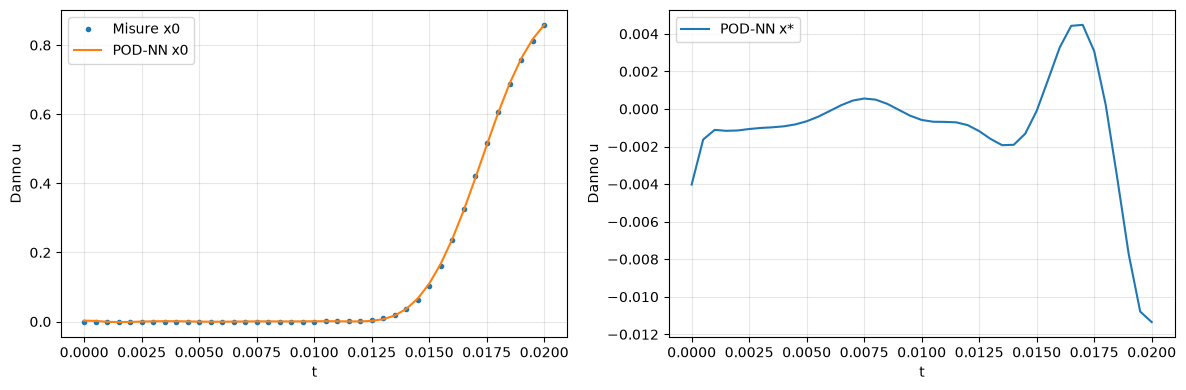

In [3]:
from dlroms.minns import Evaluate
from dlroms.cores import CPU
import dlroms.fespaces as fe

mesh, Vh = sf.build_ubolt_mesh(stepsize=0.05, knots=30)
M = sf.assemble_mass_matrix(Vh)
assert M.shape == (Vn.shape[0], Vn.shape[0])
G = Vn.T @ (M @ Vn)
print("Errore di ortonormalità M:", np.linalg.norm(G-np.eye(Vn.shape[1])))
if not np.allclose(G, np.eye(Vn.shape[1]), atol=1e-6):
    raise ValueError("Base POD non M-ortonormale: controllare mesh e artefatti.")
evaluator = Evaluate(mesh, Vh, np.array([X0, X_STAR], dtype=float))
evaluator.to(CPU)
with torch.no_grad():
    H = evaluator(torch.as_tensor(Vn.T.copy(), dtype=torch.float32)).cpu().numpy()
assert H.shape == (Vn.shape[1], 2)
h0, hstar = H[:, 0], H[:, 1]
X_known = sf.make_nn_inputs(mu_opt.reshape(1, 3), time_known)
A_known = sf.predict_coefficients(model, X_known, scaler).astype(float)
u_known = sf.reconstruct_pod(A_known, Vn)
signal_known = A_known @ hstar
sensor_known = A_known @ h0
consistency = np.max(np.abs(sensor_known-saved_prediction))
print("Differenza massima rispetto al segnale salvato nel punto III:", consistency)
if consistency > 1e-5:
    raise ValueError("Segnale del punto III non riprodotto: controllare modello, mesh e parametri.")
print("RMSE delle misure in x0:", np.sqrt(np.mean((sensor_known-measurements)**2)))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(time_known, measurements, 'o', ms=3, label='Misure x0')
axes[0].plot(time_known, sensor_known, label='POD-NN x0')
axes[1].plot(time_known, signal_known, label='POD-NN x*')
for ax in axes:
    ax.set(xlabel='t', ylabel='Danno u'); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.show()

## 3. DMD: identificare un operatore di avanzamento

Con i coefficienti **denormalizzati**, si costruiscono
$$X=[a_0-c,\ldots,a_{m-1}-c],\qquad Y=[a_1-c,\ldots,a_m-c].$$
Dalla SVD troncata $X\simeq U_q\Sigma_qW_q^T$ si ottiene
$$K_q=YW_q\Sigma_q^{-1}U_q^T,\qquad a_{k+1}=c+K_q(a_k-c).$$
La regolarizzazione opzionale sostituisce $1/\sigma_i$ con $\sigma_i/(\sigma_i^2+\alpha)$, con $\alpha=\texttt{ridge}\,\sigma_1^2$. Si avanza direttamente con $K_q$, evitando problemi di diagonalizzazione di modi quasi dipendenti.

Confrontiamo tre scelte di $c$: zero (DMD classica), media degli snapshot usati nel fit (modello affine), proiezione dell'equilibrio fisico $u\equiv1$ (dinamica del deficit di danno). Quest'ultima sfrutta l'equilibrio FKPP senza imporre autovalori stabili o tagliare le previsioni. Il campo costante potrebbe non appartenere esattamente allo spazio POD: ne misuriamo l'errore di proiezione.

Il rango DMD $q$ è distinto dai 50 modi POD: una singola traiettoria ha soltanto 40 coppie temporali e il rango numerico può essere molto inferiore. Una finestra terminale può approssimare meglio la dinamica vicina a $T$; una finestra lunga contiene più informazione ma mescola fasi non lineari diverse.

In [4]:
ones = np.ones(Vn.shape[0])
a_equilibrium = sf.project_l2(ones, Vn, M)
equilibrium_error = sf.l2_norm(ones-Vn@a_equilibrium, M)/sf.l2_norm(ones, M)
print(f"Errore L2 di proiezione di u=1: {100*equilibrium_error:.3f}%")
from itertools import product
configurations = [
    dict(rank=rank, window=window, shift=shift, ridge=ridge)
    for rank, window, shift, ridge in product(
        [2, 3, 4, 5, 6, 8, 10, 12], [None, 15, 21],
        ['zero', 'mean', 'equilibrium'], [0.0, 1e-8, 1e-6])
]
# Indici inclusivi: fit fino a 0.010, 0.0125, 0.015; previsione fino a T.
CUTOFFS = [20, 25, 30]
start = time.perf_counter()
rows, fold_rows = ef.backtest_dmd(
    A_known, configurations, CUTOFFS, G, hstar, equilibrium=a_equilibrium)
results = pd.DataFrame(rows).sort_values('score')
valid = results[results.status.eq('ok') & np.isfinite(results.score)].copy()
if valid.empty:
    raise RuntimeError("Nessuna configurazione DMD valida nei backtest.")
best_id = int(valid.iloc[0].config_id)
best_config = configurations[best_id]
print(f"Backtest: {len(valid)}/{len(configurations)} configurazioni valide, {time.perf_counter()-start:.2f} s")
print("Configurazione selezionata:", best_config)
display(valid.head(12)[['config_id','rank','window','shift','ridge','score','worst_fold','sensor_rmse']])
results.to_csv(OUTPUT / 'dmd_backtest.csv', index=False)
fold_results = pd.DataFrame(fold_rows)
display(fold_results[fold_results.config_id.eq(best_id)])

Errore L2 di proiezione di u=1: 7.111%


Backtest: 216/216 configurazioni valide, 0.21 s
Configurazione selezionata: {'rank': 10, 'window': 15, 'shift': 'equilibrium', 'ridge': 1e-08}


,config_id,rank,window,shift,ridge,score,worst_fold,sensor_rmse
178,178,10,15.0,equilibrium,1.000000e-08,0.158170,0.239238,0.084252
205,205,12,15.0,equilibrium,1.000000e-08,0.158170,0.239238,0.084252
151,151,8,15.0,equilibrium,1.000000e-08,0.158226,0.239306,0.084247
214,214,12,21.0,equilibrium,1.000000e-08,0.160148,0.241617,0.087881
187,187,10,21.0,equilibrium,1.000000e-08,0.162386,0.248239,0.090368
196,196,12,NaN,equilibrium,1.000000e-08,0.163007,0.241617,0.089111
199,199,12,15.0,zero,1.000000e-08,0.181022,0.303083,0.013107
172,172,10,15.0,zero,1.000000e-08,0.181022,0.303085,0.013107
145,145,8,15.0,zero,1.000000e-08,0.183122,0.308251,0.013213
206,206,12,15.0,equilibrium,1.000000e-06,0.190822,0.282209,0.096402


,config_id,cutoff,relative_l2,sensor_rmse
534,178,20,0.239238,0.127138
535,178,25,0.143060,0.068464
536,178,30,0.092213,0.057156


### Come viene scelta la DMD

Ogni backtest usa un prefisso della traiettoria; il futuro trattenuto non entra nel fit, nella SVD o nella media $c$. Il criterio di selezione è la media sui tre fold dell'errore spaziale relativo tra la previsione DMD e la traiettoria POD-NN trattenuta:
$$ E_b=\frac1{n_b}\sum_{j>b}\frac{\sqrt{(\hat a_j-a_j)^TG(\hat a_j-a_j)}}{\sqrt{a_j^TGa_j}},\qquad E=\frac13\sum_b E_b.$$
Il RMSE in $x^*$ è un diagnostico complementare. Gli errori nelle tabelle sono frazioni, non percentuali.

**Questa verifica misura l'accordo con il ROM**, non l'errore rispetto alla vera soluzione FKPP del bullone. Inoltre il massimo orizzonte trattenuto è $0.01$, mentre l'estrapolazione finale copre $0.02$: la qualità dei backtest non garantisce la qualità a $2T$. Il test FOM del punto I conserva il proprio ruolo; qui non viene usato per scegliere parametri o reti.

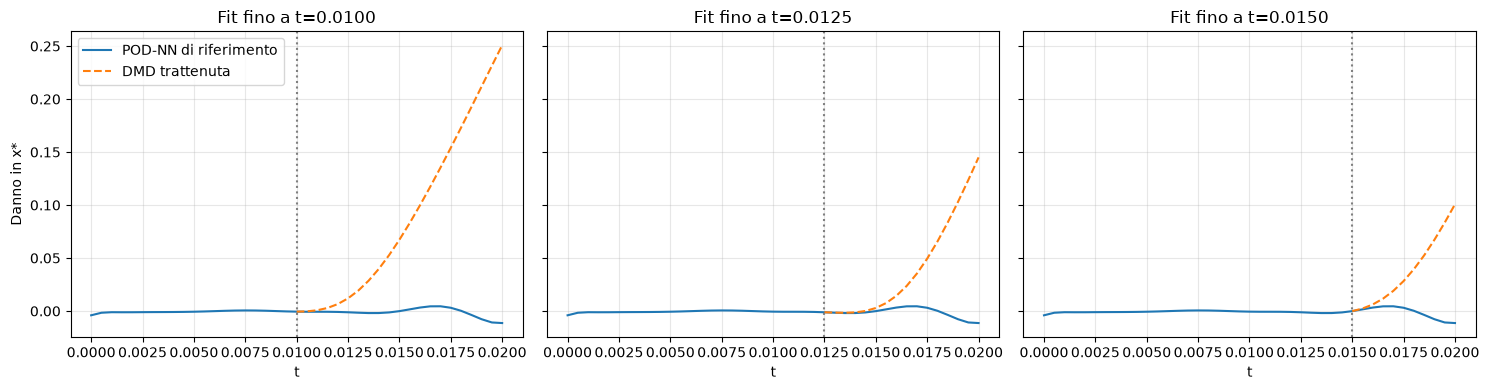

In [5]:
fig, axes = plt.subplots(1, len(CUTOFFS), figsize=(15, 4), sharey=True)
for ax, cutoff in zip(axes, CUTOFFS):
    fitted = ef.fit_dmd(A_known[:cutoff+1], equilibrium=a_equilibrium, **best_config)
    pred = ef.forecast_dmd(fitted, A_known[cutoff], len(A_known)-1-cutoff)
    ax.plot(time_known, signal_known, label='POD-NN di riferimento')
    ax.plot(time_known[cutoff:], pred@hstar, '--', label='DMD trattenuta')
    ax.axvline(time_known[cutoff], color='gray', ls=':')
    ax.set(title=f'Fit fino a t={time_known[cutoff]:.4f}', xlabel='t')
    ax.grid(alpha=.3)
axes[0].set_ylabel('Danno in x*'); axes[0].legend()
plt.tight_layout(); plt.show()

## 4. Previsione a $t^*=0.04$

Si rifà il fit della configurazione selezionata sulla traiettoria disponibile fino a $T$. La previsione parte da **$a(T)$**, con 40 avanzamenti di $\Delta t=0.0005$. Lo stato iniziale incluso nell'output è quello a $T$: non si duplicano o spostano i tempi.

Il raggio spettrale $\rho(K)$ segnala possibili amplificazioni; $\rho>1$ non viene corretto automaticamente. Gli intervalli del campo e la frazione di DOF fuori da $[0,1]$ verificano la plausibilità fisica. Un clipping nasconderebbe un eventuale fallimento della DMD, quindi tutti i calcoli e le figure usano i valori originali.

u_DMD(x*, 0.04) = 0.596225
Raggio spettrale = 0.979486
Intervallo del campo futuro = [-0.0435, 1.3600]
DOF fuori [0,1] (tol=0.001) al tempo finale: 17.22%


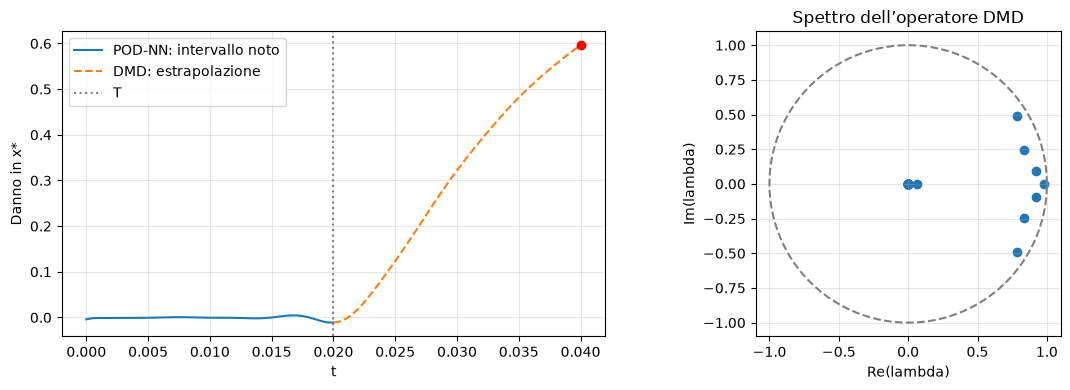

In [6]:
dmd = ef.fit_dmd(A_known, equilibrium=a_equilibrium, **best_config)
A_future = ef.forecast_dmd(dmd, A_known[-1], N_STEPS)
u_future = sf.reconstruct_pod(A_future, Vn)
signal_future = A_future @ hstar
assert np.allclose(A_future[0], A_known[-1])
assert np.isclose(time_future[-1], T_STAR)
rho = float(np.max(np.abs(dmd.eigenvalues)))
predicted_damage = float(signal_future[-1])
# Tolleranza diagnostica; nessun cambiamento dei valori calcolati.
PHYSICAL_TOL = 1e-3
violations = (u_future < -PHYSICAL_TOL) | (u_future > 1+PHYSICAL_TOL)
print(f"u_DMD(x*, 0.04) = {predicted_damage:.6f}")
print(f"Raggio spettrale = {rho:.6f}")
print(f"Intervallo del campo futuro = [{u_future.min():.4f}, {u_future.max():.4f}]")
print(f"DOF fuori [0,1] (tol={PHYSICAL_TOL:g}) al tempo finale: {100*violations[-1].mean():.2f}%")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(time_known, signal_known, label='POD-NN: intervallo noto')
axes[0].plot(time_future, signal_future, '--', label='DMD: estrapolazione')
axes[0].axvline(T, color='gray', ls=':', label='T')
axes[0].scatter([T_STAR], [predicted_damage], color='red', zorder=3)
axes[0].set(xlabel='t', ylabel='Danno in x*'); axes[0].legend(); axes[0].grid(alpha=.3)
theta = np.linspace(0, 2*np.pi, 300)
axes[1].plot(np.cos(theta), np.sin(theta), color='gray', ls='--')
axes[1].scatter(dmd.eigenvalues.real, dmd.eigenvalues.imag)
axes[1].set(xlabel='Re(lambda)', ylabel='Im(lambda)', title='Spettro dell’operatore DMD', aspect='equal')
axes[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

## 5. Sensibilità del prolungamento temporale

Si confrontano fino a 20 configurazioni con score di backtest entro il 25% dal migliore (con una tolleranza assoluta di $10^{-8}$ se lo score è quasi nullo). Nessuna configurazione viene scelta guardando la previsione a $2T$. Tutte vengono rifittate fino a $T$ e prolungate allo stesso modo.

La fascia min–max misura **sensibilità alle scelte DMD**, non è un intervallo di confidenza. Non comprende l'incertezza dei parametri identificati, l'errore del ROM o modelli dinamici non considerati. Il problema III ha evidenziato possibili ambiguità: questa previsione è condizionata a $\mu^*$, non dimostra che i parametri veri siano unici.

,config_id,rank,window,shift,ridge,score,damage_at_004,spectral_radius
0,178,10,15.0,equilibrium,1.000000e-08,0.158170,0.596225,0.979486
1,205,12,15.0,equilibrium,1.000000e-08,0.158170,0.596225,0.979486
2,151,8,15.0,equilibrium,1.000000e-08,0.158226,0.596148,0.979485
3,214,12,21.0,equilibrium,1.000000e-08,0.160148,0.580226,0.976655
4,187,10,21.0,equilibrium,1.000000e-08,0.162386,0.579579,0.976533
5,196,12,NaN,equilibrium,1.000000e-08,0.163007,0.547090,1.004375
6,199,12,15.0,zero,1.000000e-08,0.181022,0.110473,1.015659
7,172,10,15.0,zero,1.000000e-08,0.181022,0.110473,1.015659
8,145,8,15.0,zero,1.000000e-08,0.183122,0.110355,1.015671
9,206,12,15.0,equilibrium,1.000000e-06,0.190822,0.598105,0.982771


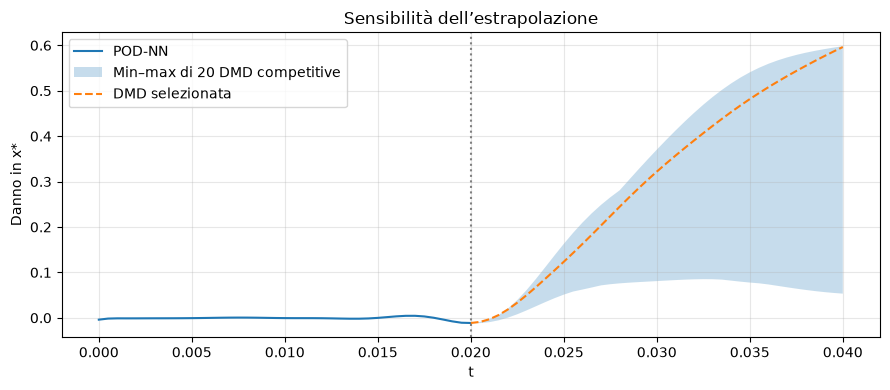

In [7]:
limit = max(float(valid.iloc[0].score)*1.25, float(valid.iloc[0].score)+1e-8)
shortlist = valid[valid.score <= limit].head(20)
ensemble, sensitivity_rows = [], []
for row in shortlist.itertuples():
    config = configurations[int(row.config_id)]
    fitted = ef.fit_dmd(A_known, equilibrium=a_equilibrium, **config)
    forecast = ef.forecast_dmd(fitted, A_known[-1], N_STEPS)
    signal = forecast@hstar
    ensemble.append(signal)
    sensitivity_rows.append(dict(config_id=row.config_id, **config, score=row.score,
        damage_at_004=float(signal[-1]), spectral_radius=float(max(abs(fitted.eigenvalues)))))
ensemble = np.stack(ensemble)
sensitivity = pd.DataFrame(sensitivity_rows)
display(sensitivity)
spread_min, spread_max = float(ensemble[:, -1].min()), float(ensemble[:, -1].max())
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(time_known, signal_known, label='POD-NN')
ax.fill_between(time_future, ensemble.min(axis=0), ensemble.max(axis=0), alpha=.25,
                label=f'Min–max di {len(ensemble)} DMD competitive')
ax.plot(time_future, signal_future, '--', label='DMD selezionata')
ax.axvline(T, color='gray', ls=':')
ax.set(xlabel='t', ylabel='Danno in x*', title='Sensibilità dell’estrapolazione')
ax.grid(alpha=.3); ax.legend(); plt.tight_layout(); plt.show()
sensitivity.to_csv(OUTPUT / 'dmd_sensitivity.csv', index=False)

## 6. Campo spaziale previsto e significato di «raggiunto»

Il campo previsto a $2T$ è confrontato con quello a $T$ usando **la stessa scala cromatica**, estesa se necessario ai valori non fisici. Il punto $x^*$ è marcato in entrambi i pannelli.

Nell'equazione diffusiva un criterio puramente $u>0$ non identifica un fronte pratico di danno: serve una soglia significativa. La consegna non ne specifica una. Riportiamo quindi il valore continuo di $u(x^*,2T)$ e, come **convenzioni operative esplicite**, le soglie 0.01, 0.05, 0.10, 0.50. Il primo superamento è valutato solo sulla griglia temporale; non è un tempo di arrivo esatto né viene assunta monotonia del segnale.

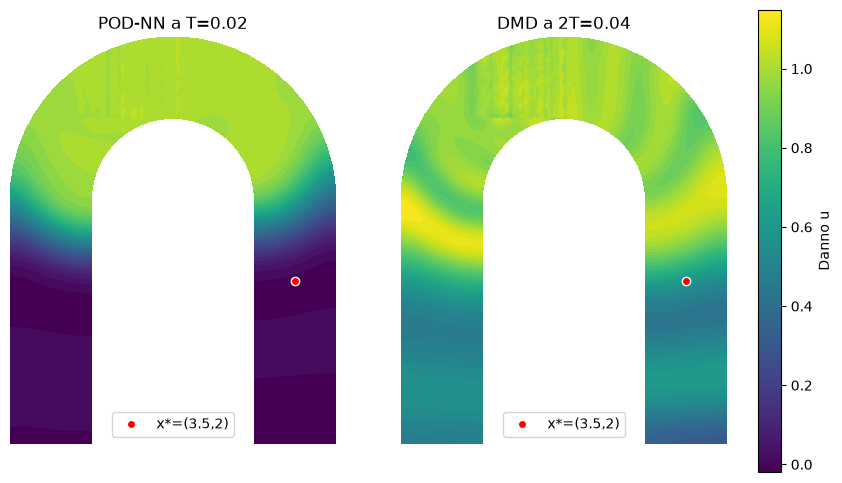

,soglia,superata_a_004,primo_superamento_griglia,tutte_DMD_superano_a_004,almeno_una_DMD_supera_a_004
0,0.01,True,0.0220,True,True
1,0.05,True,0.0230,True,True
2,0.10,True,0.0245,False,True
3,0.50,True,0.0360,False,True


In [8]:
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
fields = [u_known[-1], u_future[-1]]
vmin = min(0., min(float(f.min()) for f in fields))
vmax = max(1., max(float(f.max()) for f in fields))
levels = np.linspace(vmin-1e-8, vmax+1e-8, 100)
fig, axes = plt.subplots(1, 2, figsize=(10, 6))
for ax, field, title in zip(axes, fields, ['POD-NN a T=0.02', 'DMD a 2T=0.04']):
    plt.sca(ax)
    fe.plot(field, Vh, cmap='viridis', levels=levels, vmin=vmin, vmax=vmax)
    ax.plot(*X_STAR, 'ro', mec='white', label='x*=(3.5,2)')
    ax.set_title(title); ax.set_aspect('equal'); ax.legend(loc='lower center')
fig.colorbar(ScalarMappable(norm=Normalize(vmin, vmax), cmap='viridis'),
             ax=axes.tolist(), label='Danno u', fraction=.035, pad=.04)
plt.show()
all_times = np.concatenate([time_known, time_future[1:]])
all_signal = np.concatenate([signal_known, signal_future[1:]])
threshold_rows = []
for threshold in [.01, .05, .10, .50]:
    crossing = np.flatnonzero(all_signal >= threshold)
    threshold_rows.append(dict(soglia=threshold,
        superata_a_004=predicted_damage >= threshold,
        primo_superamento_griglia=float(all_times[crossing[0]]) if len(crossing) else np.nan,
        tutte_DMD_superano_a_004=bool(np.all(ensemble[:, -1] >= threshold)),
        almeno_una_DMD_supera_a_004=bool(np.any(ensemble[:, -1] >= threshold))))
threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table)
threshold_table.to_csv(OUTPUT / 'damage_thresholds.csv', index=False)

## 7. Risposta al punto IV e limiti

La risposta seguente viene generata dai risultati effettivamente calcolati. I valori oltre $T$ sono una **previsione POD-NN + DMD**, non misure né una soluzione FOM verificata. DMD è un'approssimazione lineare di una dinamica FKPP non lineare; l'esito dipende dal rango, dalla finestra e dall'orizzonte.

La DMD con shift di equilibrio introduce un'informazione fisica utile ma non garantisce positività, saturazione o correttezza locale. Se i backtest sono scadenti, il campo viola sensibilmente $[0,1]$ oppure le configurazioni competitive divergono, la conclusione va letta come indicazione esplorativa. Una verifica quantitativa richiederebbe un FOM fino a $0.04$; ulteriori sensori aiuterebbero a ridurre l'ambiguità dei parametri del punto III. SINDy con termini quadratici potrebbe descrivere la reazione logistica, ma 41 snapshot di una sola traiettoria non identificano automaticamente una dinamica affidabile nei 50 coefficienti.

In [9]:
score = float(valid.iloc[0].score)
physically_plausible = 0 <= predicted_damage <= 1
quality = []
if not physically_plausible:
    quality.append('Il valore puntuale è fuori dall’intervallo fisico [0,1].')
if violations.mean() > .01:
    quality.append('Oltre l’1% dei DOF-tempi estrapolati viola [0,1] con la tolleranza indicata.')
if score > .10:
    quality.append('L’errore medio dei backtest sul ROM supera il 10%; l’estrapolazione è poco affidabile.')
if spread_max-spread_min > .10:
    quality.append('La dispersione tra DMD competitive supera 0.10 in unità di danno.')
# Queste soglie sono diagnostici dichiarati, non requisiti di accuratezza del punto IV.
reference_threshold = .10
answer = ('La DMD selezionata prevede il superamento' if predicted_damage >= reference_threshold
          else 'La DMD selezionata non prevede il superamento')
text = f'''**Previsione in x*=(3.5,2) a t*=0.04:** u ≈ **{predicted_damage:.4f}**.

{answer} della soglia operativa u={reference_threshold:.2f} al tempo richiesto.
Il livello di danno stimato è {100*predicted_damage:.2f}% della scala 0–1{' (valore non fisico)' if not physically_plausible else ''}.
Le {len(ensemble)} DMD competitive producono valori tra **{spread_min:.4f} e {spread_max:.4f}**.
L’errore spaziale relativo medio nei backtest rispetto al POD-NN è **{100*score:.2f}%**.

La risposta è condizionata ai parametri identificati nel punto III e al modello di estrapolazione;
la fascia di sensibilità non è un intervallo di confidenza.'''
if quality:
    text += '\n\n**Diagnostici:** ' + ' '.join(quality)
display(Markdown(text))
(OUTPUT / 'conclusion.md').write_text(text, encoding='utf-8')
np.savez_compressed(OUTPUT / 'extrapolation_results.npz',
    mu_opt=mu_opt, physical_parameters=physical, x_star=np.array(X_STAR),
    time_known=time_known, time_future=time_future,
    coefficients_known=A_known, coefficients_future=A_future,
    signal_known=signal_known, signal_future=signal_future,
    final_field=u_future[-1], ensemble_signals=ensemble,
    dmd_operator=dmd.operator, dmd_offset=dmd.offset,
    dmd_eigenvalues=dmd.eigenvalues, best_config_id=best_id,
    backtest_score=score, predicted_damage=predicted_damage)
import json
(OUTPUT / 'selected_config.json').write_text(json.dumps(best_config, indent=2), encoding='utf-8')
print('Risultati salvati in:', OUTPUT)

**Previsione in x*=(3.5,2) a t*=0.04:** u ≈ **0.5962**.

La DMD selezionata prevede il superamento della soglia operativa u=0.10 al tempo richiesto.
Il livello di danno stimato è 59.62% della scala 0–1.
Le 20 DMD competitive producono valori tra **0.0533 e 0.5981**.
L’errore spaziale relativo medio nei backtest rispetto al POD-NN è **15.82%**.

La risposta è condizionata ai parametri identificati nel punto III e al modello di estrapolazione;
la fascia di sensibilità non è un intervallo di confidenza.

**Diagnostici:** Oltre l’1% dei DOF-tempi estrapolati viola [0,1] con la tolleranza indicata. L’errore medio dei backtest sul ROM supera il 10%; l’estrapolazione è poco affidabile. La dispersione tra DMD competitive supera 0.10 in unità di danno.

Risultati salvati in: /mnt/c/Users/Feder/Desktop/Master Courses/MOR/Python/Assignment2/artifacts/point_IV


### Interpretazione dell’esecuzione verificata

Con gli artefatti attualmente presenti, la DMD selezionata usa rango 10, gli ultimi 15 snapshot, shift verso l’equilibrio e ridge $10^{-8}$. La stima è $u(x^*,0.04)\approx0.5962$, ma il backtest medio sul ROM vale **15.82%** e le 20 configurazioni competitive prevedono livelli tra **0.0533 e 0.5981**. Al tempo finale, il **17.22% dei DOF** è fuori dall’intervallo fisico con tolleranza $10^{-3}$.

Pertanto, il modello selezionato suggerisce che il danno raggiunga il punto richiesto con intensità significativa; **il superamento della soglia 0.10 non è però robusto rispetto alla scelta DMD**. Non è giustificato presentare il 59.62% come una misura accurata o una risposta definitiva. Le tabelle delle soglie precisano quali conclusioni sono condivise dalle configurazioni competitive. Per risolvere l’incertezza quantitativa occorre una verifica della dinamica oltre $T$.

Questi numeri descrivono l’esecuzione salvata; se si cambiano artefatti o configurazioni, fare riferimento alla risposta e ai diagnostici ricalcolati nella cella precedente.
